# Data Preprocessing and Exploratory Data Analysis

## Can Historical Earnings Patterns Predict Future Earnings Surprises?

This notebook explores the Sov.ai Earnings Surprise dataset to gain a better understanding of the data and identify any issues or patterns worth further investigating.

The primary research objective is to determine whether information from a company's four preceding recorded earnings events can predict whether its next reported earnings per share exceeds analyst expectations.

### Objectives

- Examine the dataset's structure and coverage.
- Investigate missing values and repeated source records.
- Analyze earnings-event and target distributions.
- Explore historical features and their relationships.
- Document preprocessing decisions and data limitations.

**Dataset:** Sov.ai Earnings Surprise

**Methodology:** The source contains repeated observations associated with earnings events. These records are audited and reconstructed into candidate events before creating historical prediction examples.


In [1]:

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from IPython.display import display

from earnings_surprise.data.download import (
    DATASET_FILENAME,
    EXPECTED_SHA256,
    calculate_sha256,
    download_dataset,
)

from earnings_surprise.data.inspect import summarize_dataset
from earnings_surprise.data.audit_snapshots import (
    summarize_snapshot_repetition,
)


def find_project_root() -> Path:
    """locates the project root from the current directory"""
    current_directory = Path.cwd().resolve()

    for directory in [current_directory, *current_directory.parents]:
        if (directory / "pyproject.toml").is_file():
            return directory

    raise FileNotFoundError("Project root could not be located")


PROJECT_ROOT = find_project_root()

DATASET_PATH = (
    PROJECT_ROOT / "data" / "raw" / DATASET_FILENAME
)

if not DATASET_PATH.is_file():
    DATASET_PATH = download_dataset(
        PROJECT_ROOT / "data" / "raw"
    )

if calculate_sha256(DATASET_PATH) != EXPECTED_SHA256:
    raise ValueError("Dataset checksum verification failed")

raw_data = pd.read_parquet(DATASET_PATH)

print("Dataset loaded successfully")
print(f"Rows: {len(raw_data):,}")
print(f"Columns: {len(raw_data.columns)}")

Dataset loaded successfully
Rows: 1,657,661
Columns: 7


/Users/xrch/earnings-surprise-prediction/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print("Dataset Preview")
display(raw_data.head())

print("\nDataset Information")
raw_data.info()

print("\nSummary Statistics")
display(raw_data.describe(include="all"))

print("\nColumn Types")
display(
    raw_data.dtypes.to_frame(name="Data Type")
)

Dataset Preview


,ticker,date,surprise_probability,eps_surprise,actual_earning_result,estimated_earning,date_pub
0,A,2016-12-30,0.152089,0.04,0.53,0.49,2017-02-14
1,A,2017-01-06,0.216606,0.04,0.53,0.49,2017-02-14
2,A,2017-01-13,0.191768,0.04,0.53,0.49,2017-02-14
3,A,2017-01-20,0.178075,0.04,0.53,0.49,2017-02-14
4,A,2017-01-27,0.180252,0.04,0.53,0.49,2017-02-14



Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 1657661 entries, 0 to 1657660
Data columns (total 7 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   ticker                 1657661 non-null  str           
 1   date                   1657661 non-null  datetime64[ns]
 2   surprise_probability   1657661 non-null  float64       
 3   eps_surprise           1623370 non-null  float64       
 4   actual_earning_result  1623370 non-null  float64       
 5   estimated_earning      1657189 non-null  float64       
 6   date_pub               1623383 non-null  datetime64[ms]
dtypes: datetime64[ms](1), datetime64[ns](1), float64(4), str(1)
memory usage: 94.2 MB

Summary Statistics


,ticker,date,surprise_probability,eps_surprise,actual_earning_result,estimated_earning,date_pub
count,1657661,1657661,1.657661e+06,1.623370e+06,1.623370e+06,1.657189e+06,1623383
unique,5739,NaN,NaN,NaN,NaN,NaN,NaN
top,A,NaN,NaN,NaN,NaN,NaN,NaN
freq,383,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2020-10-19 11:01:53.297229312,1.151834e-04,-7.339225e+01,-2.915987e+02,-5.995336e+04,2021-02-08 07:32:28.639000
min,NaN,2016-12-30 00:00:00,-5.115261e-01,-4.702971e+06,-5.997002e+06,-2.250000e+09,2016-12-24 00:00:00
25%,NaN,2019-01-11 00:00:00,-2.312481e-01,-4.000000e-02,-1.600000e-01,-1.300000e-01,2019-05-02 00:00:00
50%,NaN,2020-11-27 00:00:00,7.497184e-04,2.000000e-02,2.000000e-01,1.800000e-01,2021-04-28 00:00:00
75%,NaN,2022-08-05 00:00:00,2.304762e-01,1.000000e-01,7.100000e-01,6.700000e-01,2022-11-14 00:00:00
max,NaN,2024-04-26 00:00:00,5.116805e-01,1.862432e+06,1.852194e+06,3.600000e+03,2024-10-30 00:00:00



Column Types


,Data Type
ticker,str
date,datetime64[ns]
surprise_probability,float64
eps_surprise,float64
actual_earning_result,float64
estimated_earning,float64
date_pub,datetime64[ms]


In [3]:
inspection = summarize_dataset(raw_data)
repetition = summarize_snapshot_repetition(raw_data)

missing_values = pd.DataFrame({
    "Missing Values": raw_data.isna().sum(),
    "Missing (%)": (
        raw_data.isna().mean() * 100
    ).round(2),
})

print("Missing Values")
display(missing_values)

print(f"Exact duplicate rows: {repetition['exact_duplicate_rows']:,}")

print(
    "Candidate earnings events: "
    f"{repetition['candidate_key_count']:,}"
)

print(
    "Candidate events with repeated records: "
    f"{repetition['keys_with_multiple_rows']:,}"
)

print(
    "Records without usable candidate keys: "
    f"{repetition['rows_without_candidate_key']:,}"
)

Missing Values


,Missing Values,Missing (%)
ticker,0,0.00
date,0,0.00
surprise_probability,0,0.00
eps_surprise,34291,2.07
actual_earning_result,34291,2.07
estimated_earning,472,0.03
date_pub,34278,2.07


Exact duplicate rows: 0
Candidate earnings events: 111,989
Candidate events with repeated records: 111,588
Records without usable candidate keys: 34,278


## Data Quality Analysis

### Missing Values

This section involves examining missing values in the original source
records, with the aim being identifying incomplete observations and
potential challenges for subsequent preprocessing.

Missingness is reported at the source-record level. Since the
dataset contains repeated records for earnings events these
figures do not necessarily represent missingness in the
reconstructed event-level dataset.

Missing Values by Column


,missing_count,missing_percent
eps_surprise,34291,2.068638
actual_earning_result,34291,2.068638
date_pub,34278,2.067853
estimated_earning,472,0.028474
ticker,0,0.000000
date,0,0.000000
surprise_probability,0,0.000000


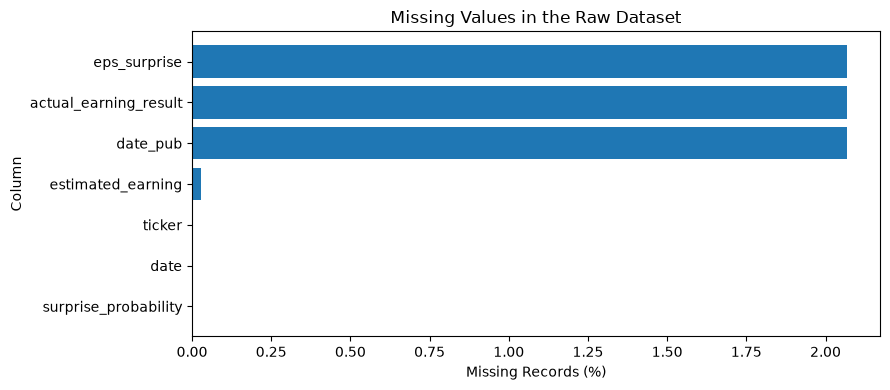

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": raw_data.isna().sum(),
    "missing_percent": raw_data.isna().mean() * 100,
})

missing_summary = missing_summary.sort_values(
    "missing_count", ascending=False
)

print("Missing Values by Column")
display(missing_summary)

fig, ax = plt.subplots(figsize=(9, 4))

ax.barh(
    missing_summary.index,
    missing_summary["missing_percent"],
)

ax.invert_yaxis()
ax.set_xlabel("Missing Records (%)")
ax.set_ylabel("Column")
ax.set_title("Missing Values in the Raw Dataset")

plt.tight_layout()
plt.show()

### Duplicate and Repeated Records

The source dataset contains repeated observations associated
with the same ticker and earnings publication date.

I distinguish exact duplicate rows from repeated candidate
earnings events. Multiple records with the same candidate key
may contain different source dates while referring to the
same recorded earnings outcome.

In [5]:
repetition_summary = summarize_snapshot_repetition(raw_data)

quality_metrics = {
    "Total source records": repetition_summary["total_rows"],
    "Exact duplicate rows": repetition_summary["exact_duplicate_rows"],
    "Candidate earnings events": repetition_summary["candidate_key_count"],
    "Events with repeated records": repetition_summary["keys_with_multiple_rows"],
    "Extra rows from repetition": repetition_summary["extra_rows_from_repetition"],
    "Rows without candidate keys": repetition_summary["rows_without_candidate_key"],
}

quality_table = pd.DataFrame(
    quality_metrics.items(),
    columns=["Metric", "Count"],
)

display(quality_table)

,Metric,Count
0,Total source records,1657661
1,Exact duplicate rows,0
2,Candidate earnings events,111989
3,Events with repeated records,111588
4,Extra rows from repetition,1511394
5,Rows without candidate keys,34278



### Data Quality Findings

The source dataset contains 1,657,661 records associated with
111,989 candidate earnings events.

Although no exact duplicate rows were identified, 111,588
candidate earnings events are associated with multiple source
records. These repetitions occur because the source contains
multiple observations associated with the same event.

The initial audit also found that many earlier-dated source
records already contain the eventual earnings result. Therefore,
the source `date` field cannot be interpreted as proof that
the financial values were available on that date.

To address these issues, I reconstruct candidate
earnings events using the provisional `(ticker, date_pub)` key.

Financial values are consolidated only after consistency
checks. Incomplete events and source-row provenance are
preserved for subsequent analysis.

## Reconstructed Earnings Events

The repeated source observations are consolidated into
candidate earnings events before constructing historical
prediction examples.

This avoids treating multiple records of the same earnings
event as independent observations

In [6]:
from earnings_surprise.data.events import (
    build_candidate_event_ledger,
)

from earnings_surprise.data.samples import (
    build_prediction_windows,
)


event_data, event_summary = build_candidate_event_ledger(raw_data)

prediction_data, prediction_summary = build_prediction_windows(
    event_data
)

dataset_stages = pd.DataFrame({
    "Dataset Stage": [
        "Original source records",
        "Reconstructed candidate events",
        "Eligible prediction samples",
    ],
    "Records": [
        len(raw_data),
        len(event_data),
        len(prediction_data),
    ],
})

display(dataset_stages)

,Dataset Stage,Records
0,Original source records,1657661
1,Reconstructed candidate events,111989
2,Eligible prediction samples,90349


,Outcome,Count
0,Beat,55576
1,Meet or Miss,34773


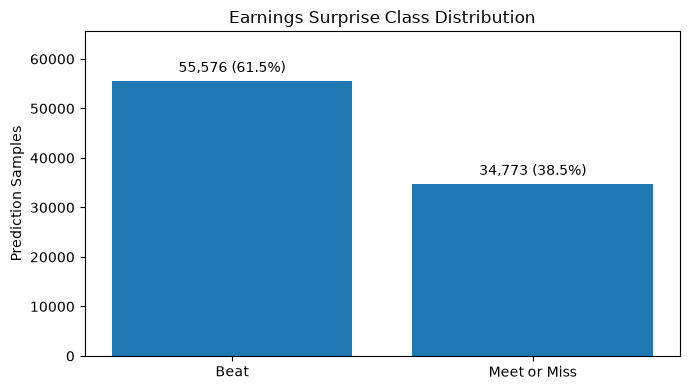

In [7]:
target_counts = pd.DataFrame({
    "Outcome": ["Beat", "Meet or Miss"],
    "Count": [
        prediction_summary["target_beats"],
        prediction_summary["target_meet_or_miss"],
    ],
})

display(target_counts)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    target_counts["Outcome"],
    target_counts["Count"],
)

labels = [
    f"{count:,} ({count / len(prediction_data):.1%})"
    for count in target_counts["Count"]
]

ax.bar_label(bars, labels=labels, padding=4)

ax.set_ylabel("Prediction Samples")
ax.set_title("Earnings Surprise Class Distribution")
ax.margins(y=0.18)

plt.tight_layout()
plt.show()